# Data Pre-processing Assignment 1
**MSc Data Science | T1-26**

Dataset: UCI Online Retail (Daqing Chen, 2015). Window: 1 September–30 November 2011 inclusive.

## Setup and data loading

In [22]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

pd.set_option('display.max_columns', None)

# Load dataset directly from GitHub
DATA_URL = "https://raw.githubusercontent.com/jaanyaraheja/Customer-Segmentation-UCI-Online-Retail-Dataset-/main/Online%20Retail.xlsx"

df = pd.read_excel(DATA_URL, engine='openpyxl')

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print('Dataset loaded successfully!')
print('Source:', DATA_URL)
print('Original shape:', df.shape)

display(df.head())

Dataset loaded successfully!
Source: https://raw.githubusercontent.com/jaanyaraheja/Customer-Segmentation-UCI-Online-Retail-Dataset-/main/Online%20Retail.xlsx
Original shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Task 1 – Dataset Understanding

In [23]:
baseline_df=df.loc[(df.InvoiceDate>='2011-09-01')&(df.InvoiceDate<'2011-12-01')].copy()
print('Baseline dimensions:',baseline_df.shape)
print('Columns:',baseline_df.columns.tolist())
display(baseline_df.dtypes.to_frame('Inferred dtype'))
baseline_df.info()
display(baseline_df.head())
display(baseline_df.describe(include='all').T)

Baseline dimensions: (195679, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,Inferred dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


<class 'pandas.core.frame.DataFrame'>
Index: 195679 entries, 320705 to 516383
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    195679 non-null  object        
 1   StockCode    195679 non-null  object        
 2   Description  195401 non-null  object        
 3   Quantity     195679 non-null  int64         
 4   InvoiceDate  195679 non-null  datetime64[ns]
 5   UnitPrice    195679 non-null  float64       
 6   CustomerID   157115 non-null  float64       
 7   Country      195679 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 13.4+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
320705,565080,20677,PINK POLKADOT BOWL,8,2011-09-01 08:25:00,1.25,13509.0,United Kingdom
320706,565080,22128,PARTY CONES CANDY ASSORTED,24,2011-09-01 08:25:00,1.25,13509.0,United Kingdom
320707,565081,21067,NaN,1,2011-09-01 09:03:00,0.00,NaN,United Kingdom
320708,565082,22423,REGENCY CAKESTAND 3 TIER,2,2011-09-01 09:15:00,12.75,13305.0,United Kingdom
320709,565082,15060B,FAIRY CAKE DESIGN UMBRELLA,8,2011-09-01 09:15:00,3.75,13305.0,United Kingdom


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,195679.0,8426.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,195679.0,3280.0,22086.0,812.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,195401,3358,PAPER CHAIN KIT 50'S CHRISTMAS,812,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,195679.0,NaN,NaN,NaN,9.508608,-4830.0,1.0,3.0,11.0,12540.0,51.68751
InvoiceDate,195679,NaN,NaN,NaN,2011-10-22 17:23:52.712145664,2011-09-01 08:25:00,2011-09-30 11:05:00,2011-10-25 15:21:00,2011-11-14 15:37:00,2011-11-30 17:42:00,NaN
UnitPrice,195679.0,NaN,NaN,NaN,4.0363,0.0,1.25,2.08,4.13,8286.22,48.88006
CustomerID,157115.0,NaN,NaN,NaN,15294.675951,12347.0,14049.0,15154.0,16753.0,18287.0,1692.017797
Country,195679,30,United Kingdom,178694,NaN,NaN,NaN,NaN,NaN,NaN,NaN


| Field | Classification | Meaning |
|---|---|---|
| InvoiceNo | Identifier | Transaction/invoice |
| StockCode | Identifier | Product |
| Description | Categorical | Product name |
| Quantity | Numeric | Units on invoice line |
| InvoiceDate | Date/time | Transaction timestamp |
| UnitPrice | Numeric | Price per unit |
| CustomerID | Identifier | Customer |
| Country | Categorical | Customer country |

Multiple rows share an InvoiceNo because each product in a transaction is stored as a separate invoice line.

## Task 2 – Data Quality Assessment

In [24]:
missing=baseline_df.isna().sum()
display(pd.DataFrame({'Missing Count':missing,'Missing Percentage':(missing/len(baseline_df)*100).round(2)}))
dup_count=int(baseline_df.duplicated().sum())
cancel_mask=baseline_df.InvoiceNo.astype(str).str.strip().str.upper().str.startswith('C')
qbad=baseline_df.Quantity<=0; pbad=baseline_df.UnitPrice<=0
print('Exact duplicates:',dup_count,'| cancellations:',int(cancel_mask.sum()),'| non-positive quantity:',int(qbad.sum()),'| non-positive price:',int(pbad.sum()))

,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,278,0.14
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,38564,19.71
Country,0,0.00


Exact duplicates: 2506 | cancellations: 3081 | non-positive quantity: 3462 | non-positive price: 664


In [25]:
text_counts={}
for col in ['Description','Country']:
    changed=baseline_df[col].notna()&(baseline_df[col].astype(str)!=baseline_df[col].astype(str).str.strip())
    text_counts[col]={'Unique before':baseline_df[col].nunique(),'Unique after trim':baseline_df[col].dropna().astype(str).str.strip().nunique(),'Whitespace rows':int(changed.sum())}
display(pd.DataFrame(text_counts).T)
invalid={}
for col in ['Quantity','UnitPrice','CustomerID']:
    conv=pd.to_numeric(baseline_df[col],errors='coerce'); invalid[col]=int((baseline_df[col].notna()&conv.isna()).sum())
print('Invalid numeric conversions:',invalid)

,Unique before,Unique after trim,Whitespace rows
Description,3358,3352,45433
Country,30,30,0


Invalid numeric conversions: {'Quantity': 0, 'UnitPrice': 0, 'CustomerID': 0}


In [26]:
def iqr_audit(s):
    x=s[s>0]; q1=x.quantile(.25); q3=x.quantile(.75); i=q3-q1; lo=q1-1.5*i; hi=q3+1.5*i
    return {'Q1':q1,'Q3':q3,'IQR':i,'Lower':lo,'Upper':hi,'Outliers':int(((x<lo)|(x>hi)).sum())}
qout=iqr_audit(baseline_df.Quantity); pout=iqr_audit(baseline_df.UnitPrice)
display(pd.DataFrame({'Quantity':qout,'UnitPrice':pout}))
issues=pd.DataFrame([
['Missing values','Description',int(missing.Description),'Incomplete product information'],['Missing values','CustomerID',int(missing.CustomerID),'Cannot attribute to customer'],['Exact duplicates','All columns',dup_count,'May double-count identical lines'],['Inconsistent text','Description',text_counts['Description']['Whitespace rows'],'Inconsistent product labels'],['Inconsistent text','Country',text_counts['Country']['Whitespace rows'],'Inconsistent country labels'],['Cancellations','InvoiceNo',int(cancel_mask.sum()),'Cancelled/reversed transactions'],['Non-positive values','Quantity',int(qbad.sum()),'Returns/invalid quantities'],['Non-positive values','UnitPrice',int(pbad.sum()),'Not ordinary positive-price sales'],['Outliers','Quantity',qout['Outliers'],'Extreme quantities'],['Outliers','UnitPrice',pout['Outliers'],'Extreme prices']],columns=['Issue','Field','Count','Potential impact'])
display(issues)

,Quantity,UnitPrice
Q1,1.0,1.25
Q3,12.0,4.13
IQR,11.0,2.88
Lower,-15.5,-3.07
Upper,28.5,8.45
Outliers,9625.0,12151.00


,Issue,Field,Count,Potential impact
0,Missing values,Description,278,Incomplete product information
1,Missing values,CustomerID,38564,Cannot attribute to customer
2,Exact duplicates,All columns,2506,May double-count identical lines
3,Inconsistent text,Description,45433,Inconsistent product labels
4,Inconsistent text,Country,0,Inconsistent country labels
5,Cancellations,InvoiceNo,3081,Cancelled/reversed transactions
6,Non-positive values,Quantity,3462,Returns/invalid quantities
7,Non-positive values,UnitPrice,664,Not ordinary positive-price sales
8,Outliers,Quantity,9625,Extreme quantities
9,Outliers,UnitPrice,12151,Extreme prices


Outlier thresholds are calculated on positive values using 1.5×IQR. Outliers are flags, not necessarily errors. Cancellation, quantity and price issue counts can overlap and must not be summed to estimate unique affected rows.

## Task 3 – Data Cleaning

In [27]:
clean_df=baseline_df.copy(); stages=[('Original baseline',len(clean_df),0)]
b=len(clean_df); clean_df=clean_df.drop_duplicates().copy(); stages.append(('After duplicate removal',len(clean_df),b-len(clean_df)))
b=len(clean_df); cm=clean_df.InvoiceNo.astype(str).str.strip().str.upper().str.startswith('C'); clean_df=clean_df.loc[~cm].copy(); stages.append(('After cancellation removal',len(clean_df),b-len(clean_df)))
b=len(clean_df); clean_df=clean_df.loc[clean_df.Quantity>0].copy(); stages.append(('After non-positive quantity removal',len(clean_df),b-len(clean_df)))
b=len(clean_df); clean_df=clean_df.loc[clean_df.UnitPrice>0].copy(); stages.append(('After non-positive price removal',len(clean_df),b-len(clean_df)))
b=len(clean_df); clean_df=clean_df.dropna(subset=['CustomerID']).copy(); stages.append(('After missing CustomerID removal',len(clean_df),b-len(clean_df)))
clean_df['Description']=clean_df.Description.str.strip().str.upper(); clean_df['Country']=clean_df.Country.str.strip(); clean_df['StockCode']=clean_df.StockCode.astype(str).str.strip()
display(pd.DataFrame(stages,columns=['Cleaning stage','Remaining rows','Rows removed at stage']))

,Cleaning stage,Remaining rows,Rows removed at stage
0,Original baseline,195679,0
1,After duplicate removal,193173,2506
2,After cancellation removal,190105,3068
3,After non-positive quantity removal,189724,381
4,After non-positive price removal,189441,283
5,After missing CustomerID removal,151630,37811


In [28]:
required=['InvoiceNo','StockCode','InvoiceDate','Quantity','UnitPrice','CustomerID']
assert clean_df[required].notna().all().all() and (clean_df.Quantity>0).all() and (clean_df.UnitPrice>0).all()
assert not clean_df.duplicated().any() and not clean_df.InvoiceNo.astype(str).str.startswith('C').any()
print('Cleaned shape:',clean_df.shape,'| Unique customers:',clean_df.CustomerID.nunique())
print('All required-field and completed-sales checks passed.')

Cleaned shape: (151630, 8) | Unique customers: 2851
All required-field and completed-sales checks passed.


Cleaning decisions: remove exact duplicate rows, cancellations, non-positive quantity/price lines and missing CustomerIDs; trim and uppercase descriptions; retain IQR outliers as they may be genuine. Missing descriptions are not imputed because StockCode identifies products. TotalSpend represents positive-price completed-sales value, not net revenue after returns/refunds.

## Task 4 – Data Transformation and Aggregation

In [29]:
ref_date=pd.Timestamp('2011-12-01'); clean_df['LineSpend']=clean_df.Quantity*clean_df.UnitPrice
customer_features=clean_df.groupby('CustomerID').agg(LastPurchase=('InvoiceDate','max'),PurchaseFrequency=('InvoiceNo','nunique'),TotalSpend=('LineSpend','sum'),ProductVariety=('StockCode','nunique')).reset_index()
customer_features['Recency']=(ref_date-customer_features.LastPurchase.dt.normalize()).dt.days
customer_features=customer_features.drop(columns='LastPurchase'); customer_features.CustomerID=customer_features.CustomerID.astype('int64')
original_features=['Recency','PurchaseFrequency','TotalSpend','ProductVariety']
customer_features=customer_features[['CustomerID']+original_features].copy()
print('Customer table shape:',customer_features.shape); display(customer_features.head(10)); display(customer_features[original_features].describe().T)

Customer table shape: (2851, 5)


,CustomerID,Recency,PurchaseFrequency,TotalSpend,ProductVariety
0,12347,31,1,1294.32,47
1,12348,67,1,310.00,3
2,12349,10,1,1757.55,73
3,12352,28,3,944.23,39
4,12356,14,1,58.35,2
5,12357,25,1,6207.67,131
6,12359,49,1,2814.30,100
7,12360,44,1,1043.78,54
8,12362,27,5,2949.84,114
9,12364,32,2,378.86,23


,count,mean,std,min,25%,50%,75%,max
Recency,2851.0,30.884251,24.189528,1.00,10.000,24.0,49.000,91.00
PurchaseFrequency,2851.0,2.224132,3.080885,1.00,1.000,1.0,2.000,86.00
TotalSpend,2851.0,1102.258247,4212.769576,3.35,262.185,491.2,995.905,117634.53
ProductVariety,2851.0,42.663276,58.400819,1.00,14.000,28.0,54.000,1167.00


,count,mean,std,min,25%,50%,75%,max
TotalSpend,2851.0,1102.258247,4212.769576,3.350000,262.185000,491.200000,995.905000,117634.530000
Log_TotalSpend,2851.0,6.246769,1.060972,1.470176,5.572857,6.198885,6.904655,11.675346


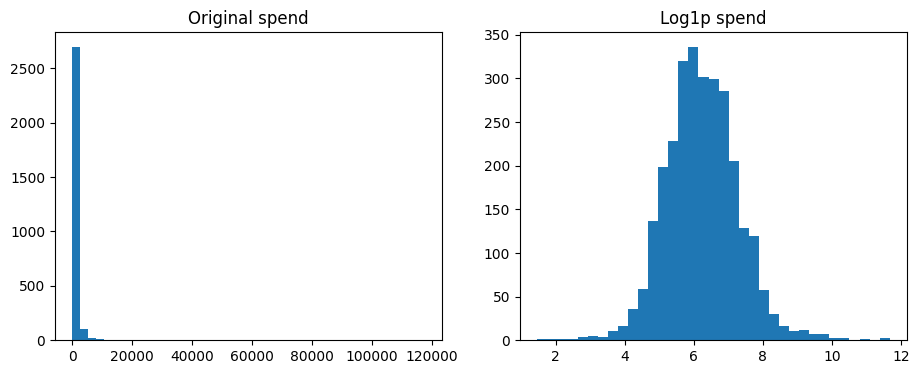

In [30]:
customer_features['Log_TotalSpend']=np.log1p(customer_features.TotalSpend)
display(customer_features[['TotalSpend','Log_TotalSpend']].describe().T)
fig,ax=plt.subplots(1,2,figsize=(11,4)); ax[0].hist(customer_features.TotalSpend,bins=45); ax[0].set_title('Original spend'); ax[1].hist(customer_features.Log_TotalSpend,bins=35); ax[1].set_title('Log1p spend'); plt.show()

In [31]:
scaler=StandardScaler(); scaled_cols=['Recency_Scaled','Frequency_Scaled','Spend_Scaled','Variety_Scaled']
customer_features[scaled_cols]=scaler.fit_transform(customer_features[original_features])
display(customer_features[scaled_cols].agg(['mean','std']).T)

,mean,std
Recency_Scaled,2.243032e-17,1.000175
Frequency_Scaled,3.987613e-17,1.000175
Spend_Scaled,-2.990710e-17,1.000175
Variety_Scaled,1.557661e-17,1.000175


,Customers
Recency_Category,
Recent,1664
Warm,742
Cooling,434
Lapsed,11


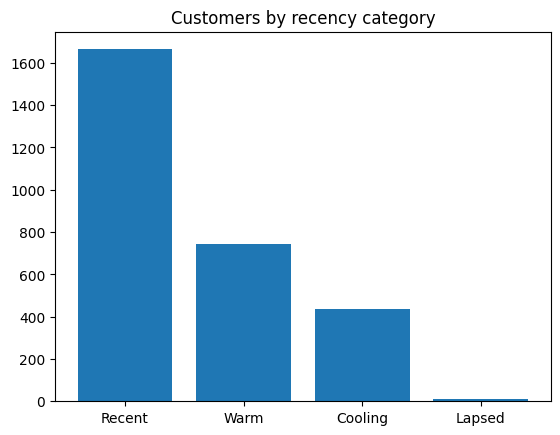

In [32]:
customer_features['Recency_Category']=pd.cut(customer_features.Recency,bins=[0,30,60,90,np.inf],labels=['Recent','Warm','Cooling','Lapsed'],include_lowest=True)
recency_counts=customer_features.Recency_Category.value_counts().reindex(['Recent','Warm','Cooling','Lapsed']); display(recency_counts.to_frame('Customers'))
plt.bar(recency_counts.index.astype(str),recency_counts.values); plt.title('Customers by recency category'); plt.show()

In [33]:
export_cols=['CustomerID']+original_features+['Log_TotalSpend']+scaled_cols+['Recency_Category']
customer_features[export_cols].to_csv('cleaned_customer_features.csv',index=False)
print('Exported CSV rows:',len(customer_features))

Exported CSV rows: 2851


The log1p transform compresses right-skewed spend. StandardScaler makes the four numeric features comparable for distance calculations. Recency bins provide marketing-readable activity groups. The CSV retains original business-unit features and adds transformed columns.

## Task 5 – Data Reduction

In [34]:
corr=customer_features[original_features].corr(); display(corr)
threshold=.65; upper=corr.abs().where(np.triu(np.ones(corr.shape),k=1).astype(bool))
features_to_drop=[col for col in upper.columns if (upper[col]>=threshold).any()]
selected_features=[col for col in original_features if col not in features_to_drop]
selected_table=customer_features[selected_features].copy()
print('Dropped:',features_to_drop,'| Retained:',selected_features)
print('Feature selection before:',(len(customer_features),len(original_features)),'after:',selected_table.shape)

,Recency,PurchaseFrequency,TotalSpend,ProductVariety
Recency,1.000000,-0.292825,-0.130005,-0.240871
PurchaseFrequency,-0.292825,1.000000,0.601219,0.673545
TotalSpend,-0.130005,0.601219,1.000000,0.407796
ProductVariety,-0.240871,0.673545,0.407796,1.000000


Dropped: ['ProductVariety'] | Retained: ['Recency', 'PurchaseFrequency', 'TotalSpend']
Feature selection before: (2851, 4) after: (2851, 3)


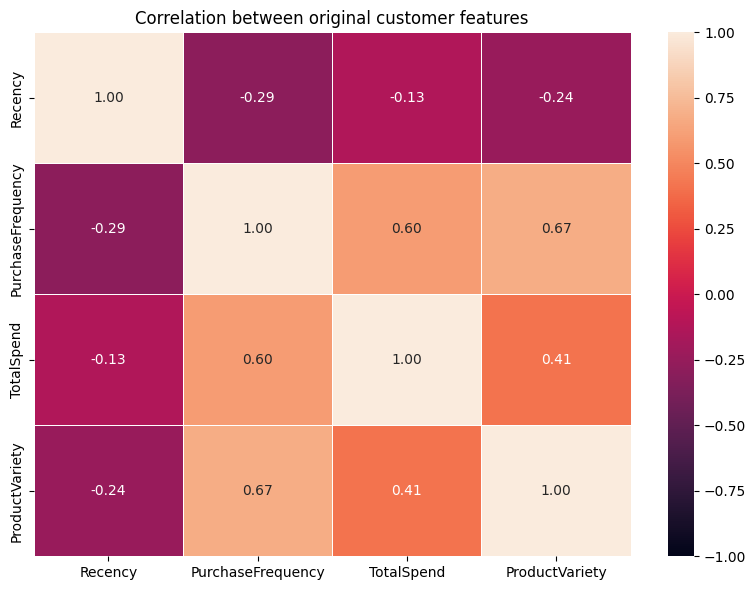

In [35]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='rocket',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation between original customer features')
plt.tight_layout()
plt.show()

Explained variance: [0.56260222 0.22534541 0.14460427 0.0674481 ]
Cumulative variance: [0.56260222 0.78794763 0.9325519  1.        ]
Retained components: 3 | cumulative retained: 0.9325519032624003
PCA before: (2851, 4) after: (2851, 3)


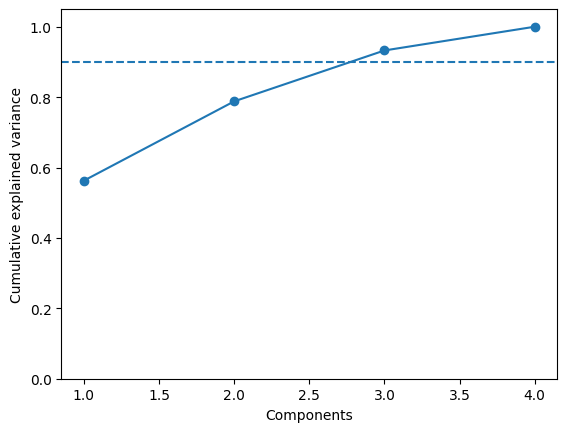

In [36]:
pca_full=PCA().fit(customer_features[scaled_cols]); explained=pca_full.explained_variance_ratio_; cumulative=np.cumsum(explained)
n_components=int(np.argmax(cumulative>=.90)+1); pca_reduced=PCA(n_components=n_components); pca_values=pca_reduced.fit_transform(customer_features[scaled_cols])
print('Explained variance:',explained); print('Cumulative variance:',cumulative); print('Retained components:',n_components,'| cumulative retained:',cumulative[n_components-1])
print('PCA before:',(len(customer_features),4),'after:',pca_values.shape)
plt.plot(range(1,5),cumulative,marker='o'); plt.axhline(.90,ls='--'); plt.ylim(0,1.05); plt.xlabel('Components'); plt.ylabel('Cumulative explained variance'); plt.show()

Correlation selection at |r| ≥ 0.65 removes ProductVariety because it correlates 0.674 with PurchaseFrequency. It retains three interpretable business features but loses product-breadth information. PCA retains three components explaining approximately 93.26% of variance; it preserves combined variation but is less directly interpretable. Both methods retain all customer rows.

## Task 6 – Proximity Measures

In [37]:
RANDOM_SEED=42; sample20=customer_features.sample(20,random_state=RANDOM_SEED).sort_values('CustomerID').copy()
ids=sample20.CustomerID.astype(str).tolist(); X=sample20[scaled_cols].to_numpy()
euc=pairwise_distances(X,metric='euclidean'); man=pairwise_distances(X,metric='manhattan')
print('Seed:',RANDOM_SEED,'| sampled IDs:',ids)
display(pd.DataFrame(euc,index=ids,columns=ids).round(3)); display(pd.DataFrame(man,index=ids,columns=ids).round(3))

Seed: 42 | sampled IDs: ['12691', '12987', '13169', '13539', '13860', '14416', '14495', '14514', '14581', '15264', '15436', '15603', '16012', '16722', '16987', '17034', '17221', '17594', '17668', '17865']


,12691,12987,13169,13539,13860,14416,14495,14514,14581,15264,15436,15603,16012,16722,16987,17034,17221,17594,17668,17865
12691,0.000,1.891,1.485,2.382,1.102,0.253,0.976,1.440,0.607,1.540,2.274,2.100,0.675,1.075,0.944,0.545,0.582,2.421,0.532,2.518
12987,1.891,0.000,0.431,0.498,2.699,2.134,0.967,0.564,2.357,0.404,3.303,0.296,1.633,2.603,1.562,2.385,1.554,0.631,1.451,3.279
13169,1.485,0.431,0.000,0.923,2.366,1.730,0.541,0.396,1.950,0.281,3.085,0.627,1.288,2.281,1.308,1.991,1.184,1.042,1.034,3.132
13539,2.382,0.498,0.923,0.000,3.148,2.626,1.463,1.019,2.853,0.877,3.676,0.381,2.108,3.045,1.978,2.875,2.041,0.353,1.948,3.557
13860,1.102,2.699,2.366,3.148,0.000,0.960,1.949,2.202,1.144,2.332,1.645,2.940,1.323,0.184,1.203,0.795,1.385,3.102,1.568,1.751
14416,0.253,2.134,1.730,2.626,0.960,0.000,1.216,1.668,0.420,1.775,2.164,2.348,0.781,0.961,1.083,0.303,0.730,2.655,0.746,2.509
14495,0.976,0.967,0.541,1.463,1.949,1.216,0.000,0.636,1.421,0.668,2.789,1.158,0.876,1.882,1.073,1.484,0.730,1.554,0.501,2.972
14514,1.440,0.564,0.396,1.019,2.202,1.668,0.636,0.000,1.877,0.167,2.762,0.851,1.094,2.106,1.076,1.892,1.039,1.000,1.022,2.914
14581,0.607,2.357,1.950,2.853,1.144,0.420,1.421,1.877,0.000,1.989,2.107,2.575,0.887,1.180,1.385,0.363,0.861,2.876,0.920,2.807
15264,1.540,0.404,0.281,0.877,2.332,1.775,0.668,0.167,1.989,0.000,2.923,0.686,1.234,2.238,1.206,2.012,1.166,0.899,1.107,3.021


,12691,12987,13169,13539,13860,14416,14495,14514,14581,15264,15436,15603,16012,16722,16987,17034,17221,17594,17668,17865
12691,0.000,2.307,1.888,2.823,2.002,0.302,1.431,2.040,1.004,2.056,2.861,2.631,1.174,2.031,1.639,0.748,1.080,3.174,0.848,4.171
12987,2.307,0.000,0.544,0.545,4.172,2.506,1.163,0.832,2.419,0.559,5.032,0.461,2.023,4.201,2.651,2.919,1.833,0.974,1.572,6.176
13169,1.888,0.544,0.000,1.089,3.890,2.190,0.618,0.550,2.114,0.360,4.749,0.744,1.741,3.918,2.369,2.636,1.528,1.518,1.062,5.894
13539,2.823,0.545,1.089,0.000,4.620,3.022,1.708,1.279,2.895,1.007,5.479,0.593,2.486,4.648,3.099,3.366,2.309,0.429,2.117,6.623
13860,2.002,4.172,3.890,4.620,0.000,1.700,3.433,3.340,1.809,3.613,2.320,4.634,2.149,0.276,1.521,1.254,2.398,4.191,2.850,3.327
14416,0.302,2.506,2.190,3.022,1.700,0.000,1.733,2.234,0.708,2.255,2.559,2.933,1.374,1.729,1.833,0.446,1.280,3.368,1.150,4.365
14495,1.431,1.163,0.618,1.708,3.433,1.733,0.000,1.003,1.624,0.978,4.292,1.200,1.284,3.462,1.912,2.179,1.036,2.136,0.583,5.437
14514,2.040,0.832,0.550,1.279,3.340,2.234,1.003,0.000,2.190,0.273,4.201,1.293,1.336,3.369,1.819,2.292,1.159,1.134,1.412,5.344
14581,1.004,2.419,2.114,2.895,1.809,0.708,1.624,2.190,0.000,2.165,2.668,2.825,1.231,1.920,2.438,0.555,1.068,3.324,1.052,4.970
15264,2.056,0.559,0.360,1.007,3.613,2.255,0.978,0.273,2.165,0.000,4.472,1.020,1.516,3.641,2.092,2.359,1.340,1.158,1.387,5.617


In [38]:
def closest_pairs(mat,ids):
    mask=~np.eye(len(ids),dtype=bool); mn=float(mat[mask].min()); out=[]
    for i in range(len(ids)):
        for j in range(i+1,len(ids)):
            if abs(float(mat[i,j])-mn)<1e-12: out.append((ids[i],ids[j],float(mat[i,j])))
    return mn,out
e_min,e_pairs=closest_pairs(euc,ids); m_min,m_pairs=closest_pairs(man,ids)
print('Euclidean closest pair(s):',e_pairs,'minimum:',e_min)
print('Manhattan closest pair(s):',m_pairs,'minimum:',m_min)
print('Ties? Euclidean:',len(e_pairs)>1,'Manhattan:',len(m_pairs)>1)
for metric,pairs in [('Euclidean',e_pairs),('Manhattan',m_pairs)]:
    for a,b,d in pairs:
        ra=customer_features.loc[customer_features.CustomerID.astype(str)==a].iloc[0]; rb=customer_features.loc[customer_features.CustomerID.astype(str)==b].iloc[0]
        print(metric,a,b,d); display(pd.DataFrame({'Feature':original_features,'Customer '+a:[ra[f] for f in original_features],'Customer '+b:[rb[f] for f in original_features]}))

Euclidean closest pair(s): [('14514', '15264', 0.16748899929705396)] minimum: 0.16748899929705396
Manhattan closest pair(s): [('16012', '17221', 0.2484315429644528)] minimum: 0.2484315429644528
Ties? Euclidean: False Manhattan: False
Euclidean 14514 15264 0.16748899929705396


,Feature,Customer 14514,Customer 15264
0,Recency,53.00,56.00
1,PurchaseFrequency,1.00,1.00
2,TotalSpend,587.09,393.74
3,ProductVariety,29.00,23.00


Manhattan 16012 17221 0.2484315429644528


,Feature,Customer 16012,Customer 17221
0,Recency,27.00,28.00
1,PurchaseFrequency,1.00,1.00
2,TotalSpend,283.17,132.28
3,ProductVariety,40.00,30.00


Euclidean distance squares standardized differences; Manhattan distance sums absolute standardized differences. They can therefore identify different closest pairs. Both use the same 20 customers and same four scaled features; CustomerID is a label only.

## Task 7 – Reflection and Explainability

###Reflection

I found it difficult to convert data from an invoice level to reliable customer data. It was essential to ensure that the data still correctly represented the customer’s behaviour. Although each row represents an invoice, there are issues including: missing customer information, cancelled invoices, negative quantities, zero prices and also instances of multiple and incorrect data. Small data preparation decisions can impact which customers are analysed together and how far apart these groups are.

Excluding data with a missing CustomerID had an impact. Initially there were 38,564 rows lacking a CustomerID (19.71%). Following the deletion of duplicates, cancelled and incorrect data, a further 37,811 rows were then removed due to missing CustomerIDs. There were 151,630 rows within the ‘sales’ section of the dataset and 2,851 identifiable customers, which accounted for the final subset. Therefore, my customer analyses relate only to those customers for whom we have information. Not all of a retailer’s behaviour is analysed. Also, the sequence of data exclusions is important given that there are interlinking issues. Firstly, I identified 3,081 cancelled rows. Of these, 3,068 were subsequently deleted following the removal of duplicates.

Secondly, there was an impact from excluding cancelled, and negative price and quantity data. Converting ‘TotalSpend’, which is equal to quantity multiplied by unit price, to a positive value simplifies its understanding. However, this is not net sales as it does not account for returns and exchanges. Therefore, a marketing team may incorrectly assess a customer’s ongoing value if this individual frequently returns goods. Again, this exclusion process is appropriate for sales data. Additional functionality would be required to analyse returns behaviour to fully understand a customer’s value.

How I managed outliers also influences results. Based on IQR, 9,625 quantity and 12,151 positive unit price data points were recognised as outliers. As large orders and/or expensive items may legitimately occur, I elected to retain this data. Although removing outliers would result in more ‘average’ data, it could also exclude bulk and/or high spend customers. Log1p was applied to ‘TotalSpend’ to reduce the long tail of the distribution. Subsequently, StandardScaler normalises recency, frequency and product variety so that they can be used to measure distances. Without normalisation, the distance calculation may be unduly influenced by the £’s value as these can be significantly higher. However, whilst normalisation equalises data ranges, it does not imply that all features are of equivalent business importance.

Feature reduction too involves a compromise. Using correlation, ProductVariety was excluded as it is sufficiently correlated (at my selected cut off point of 0.65) to PurchaseFrequency. Therefore, there is some loss of data regarding the range of goods that customers buy. PCA reduces data to 3 components representing around 93.26% of the original features’ variance. Yet, these components are less easily understood than the initial features. A marketing team must not presume that such a data summary will capture all differences.

There is still an issue to note. Analysis is based on 3 month data. Individuals who purchased goods prior to September but not in the 3 month period may be deemed disengaged and potentially even not be represented. Consequently, the recency feature reflects behaviour in this 3 month time frame rather than long-term engagement.

For segmenting customers, I advise performing K-means clustering on log transformed TotalSpend along with normalised recency, frequency and product variety. Rather than arbitrarily deciding on a value for k, several options should be assessed. Following this, I would determine the silhouette score. Examination of cluster size and characteristics should also occur. Furthermore, I would investigate the extent to which results are consistently obtained from different initialisations. This will aid in confirming that clusters are both statistically separate and also practically suitable for guiding marketing strategy.

## Final checks

In [39]:
print('Baseline:',len(baseline_df),'| Clean invoice lines:',len(clean_df),'| Customer records:',len(customer_features))
print('Customer feature shape:',customer_features.shape,'| CSV exported:',os.path.exists('cleaned_customer_features.csv'))

Baseline: 195679 | Clean invoice lines: 151630 | Customer records: 2851
Customer feature shape: (2851, 11) | CSV exported: True
